 Step 1 :

 Load, pre - process and add a Noise to the Dataset:

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


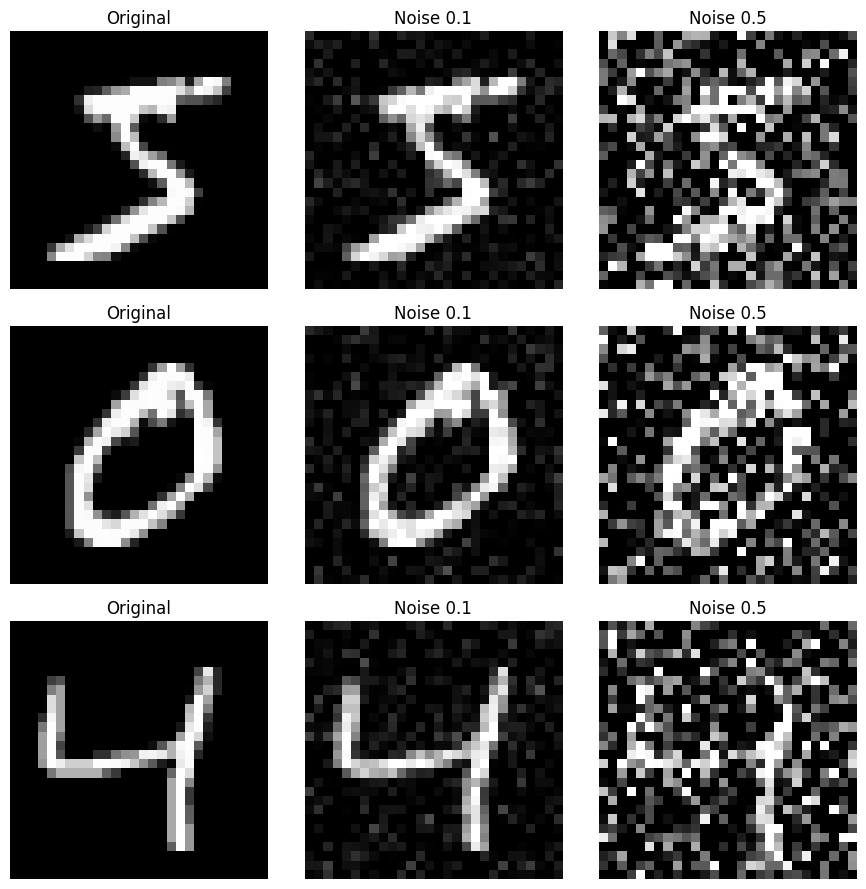

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.datasets import mnist

# Load and preprocess MNIST
(x_train, _), (x_test, _) = mnist.load_data()
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))
x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))

# Generate noisy versions
noise_factor_low = 0.1
noise_factor_high = 0.5

x_train_noisy_low = x_train + noise_factor_low * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_train_noisy_high = x_train + noise_factor_high * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)

x_test_noisy_low = x_test + noise_factor_low * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
x_test_noisy_high = x_test + noise_factor_high * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)

# Clip pixel values to [0, 1]
x_train_noisy_low = np.clip(x_train_noisy_low, 0., 1.)
x_test_noisy_low = np.clip(x_test_noisy_low, 0., 1.)
x_train_noisy_high = np.clip(x_train_noisy_high, 0., 1.)
x_test_noisy_high = np.clip(x_test_noisy_high, 0., 1.)

# Visualize in a 3 x 3 grid
n = 3  # number of images to show
plt.figure(figsize=(9, 9))

for i in range(n):
    # Original image
    ax = plt.subplot(n, 3, i * 3 + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Low noise image
    ax = plt.subplot(n, 3, i * 3 + 2)
    plt.imshow(x_train_noisy_low[i].reshape(28, 28), cmap='gray')
    plt.title("Noise 0.1")
    plt.axis('off')

    # High noise image
    ax = plt.subplot(n, 3, i * 3 + 3)
    plt.imshow(x_train_noisy_high[i].reshape(28, 28), cmap='gray')
    plt.title("Noise 0.5")
    plt.axis('off')

plt.tight_layout()
plt.show()

Step 2: Build the Convolutional Denoising Autoencoder Model:

building encoder

In [ ]:
def build_encoder(input_shape=(28, 28, 1)):
    """
    Builds the encoder part of the convolutional autoencoder.

    Parameters:
    input_shape (tuple): Shape of the input image. Default is (28, 28, 1) for MNIST.

    Returns:
    input_img (Keras Input): Input layer of the model.
    encoded (Keras Tensor): Encoded representation after convolution and pooling.
    """
    input_img = Input(shape=input_shape, name="input")

    # First block
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)

    # Second block
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    encoded = MaxPooling2D((2, 2), padding='same', name="encoded")(x)

    return input_img, encoded

Building Decoder.

In [ ]:
def build_decoder(encoded_input):
    """
    Builds the decoder part of the convolutional autoencoder.

    Parameters:
    encoded_input (Keras Tensor): The output from the encoder.

    Returns:
    decoded (Keras Tensor): The reconstructed output after upsampling and
    convolution.
    """
    # First reconstruction block
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(encoded_input)
    x = UpSampling2D((2, 2))(x)

    # Second reconstruction block
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)

    # Final output layer
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same', name="decoded")(x)

    return decoded

Building Autoencdoder.

In [ ]:
def build_autoencoder():
    """
    Constructs and compiles the full convolutional autoencoder by connecting encoder and
    decoder.

    Returns:
    autoencoder (Keras Model): Compiled autoencoder model.
    """
    # Instantiate the encoder components
    input_img, encoded_output = build_encoder()

    # Pass encoder output into the decoder
    decoded_output = build_decoder(encoded_output)

    # Define the full model
    autoencoder = Model(inputs=input_img, outputs=decoded_output, name="autoencoder")

    # Compile with Adam optimizer and binary crossentropy loss
    autoencoder.compile(optimizer=Adam(), loss='binary_crossentropy')

    return autoencoder

Compile the Model.

In [ ]:
autoencoder = build_autoencoder()
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoded (MaxPooling2D)          │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoded (Conv2D)                │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

Step 3: Train the Autoencoder:

In [ ]:
# Build the autoencoder from previous steps
autoencoder = build_autoencoder()
# Train with noisy input and clean target
history = autoencoder.fit(
x_train_noisy_high, x_train,
epochs=10,
batch_size=128,
shuffle=True,
validation_data=(x_test_noisy_high, x_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - loss: 0.2369 - val_loss: 0.1144
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.1124 - val_loss: 0.1056
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1054 - val_loss: 0.1019
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1024 - val_loss: 0.0998
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.1003 - val_loss: 0.0984
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0990 - val_loss: 0.0975
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0980 - val_loss: 0.0968
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0973 - val_loss: 0.0972
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0966 - val_loss: 0.0958
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0962 - val_loss: 0.0952


Step 4: Evaluate the Autoencoder:

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


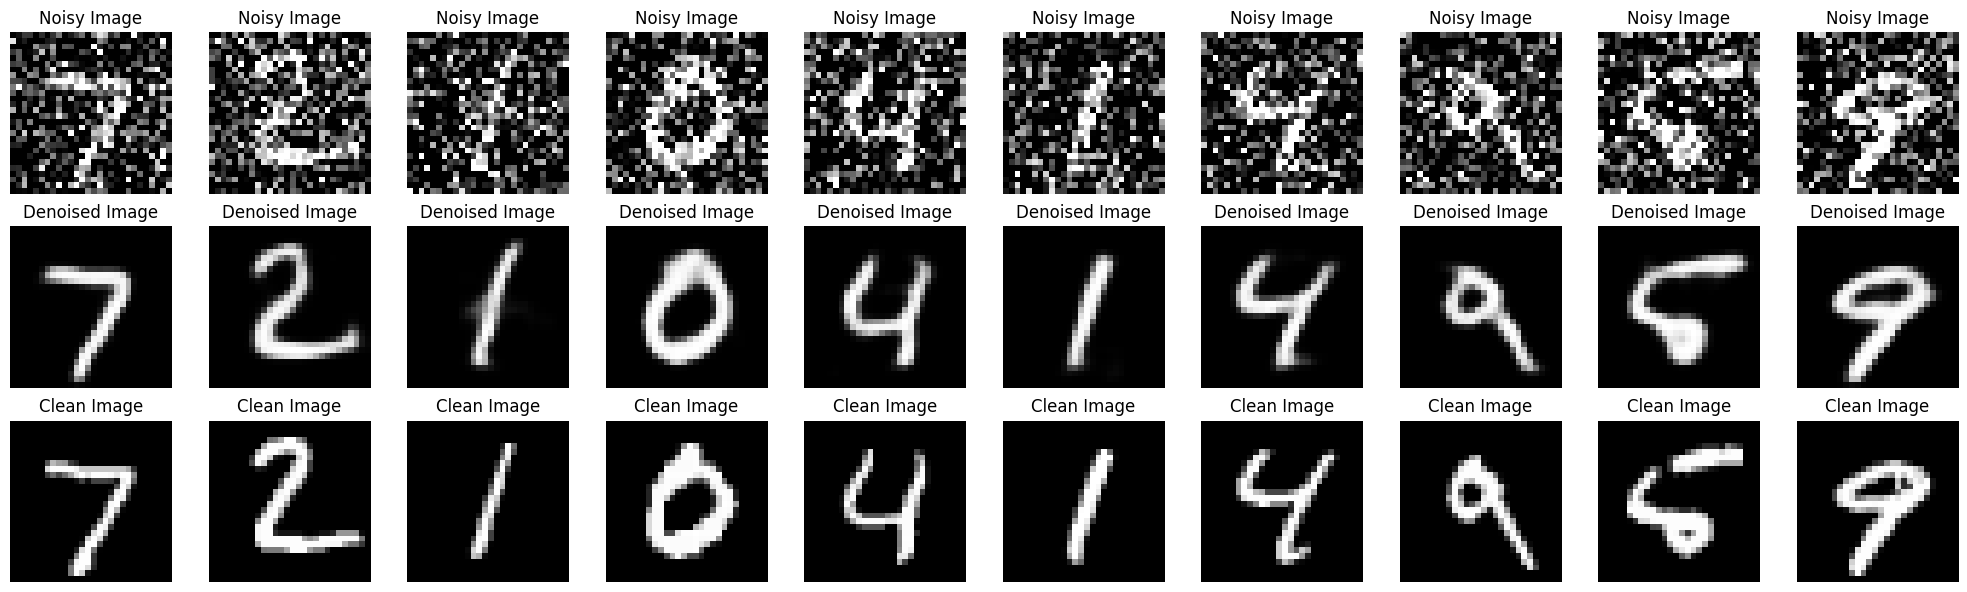

In [ ]:
# Predict the denoised images from noisy test images
denoised_images = autoencoder.predict(x_test_noisy_high)

# Function to display images
def plot_images(noisy_images, denoised_images, clean_images, n=10):
    plt.figure(figsize=(20, 6))
    for i in range(n):
        # Plot noisy images
        plt.subplot(3, n, i + 1)
        plt.imshow(noisy_images[i].reshape(28, 28), cmap='gray')
        plt.title("Noisy Image")
        plt.axis('off')

        # Plot denoised images
        plt.subplot(3, n, i + 1 + n)
        plt.imshow(denoised_images[i].reshape(28, 28), cmap='gray')
        plt.title("Denoised Image")
        plt.axis('off')

        # Plot clean images
        plt.subplot(3, n, i + 1 + 2 * n)
        plt.imshow(clean_images[i].reshape(28, 28), cmap='gray')
        plt.title("Clean Image")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Display the first 10 images
plot_images(x_test_noisy_high, denoised_images, x_test, n=10)

Exercise: Build a Denoising Convolutional Autoencoder

Dataset: Devnagari Handwritten Digit Dataset:

1. Dataset Preparation and Preprocessing:

Saving Copy of devnagari digit.zip to Copy of devnagari digit.zip
Training shape: (16000, 28, 28, 1)
Validation shape: (4000, 28, 28, 1)


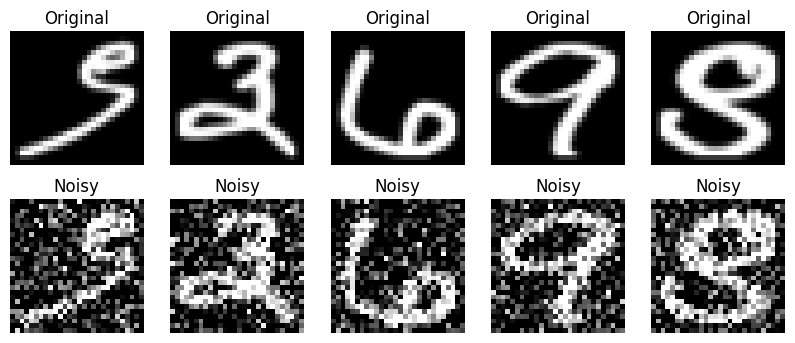

In [ ]:
import os
import zipfile
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()

zip_path = list(uploaded.keys())[0]
extract_path = 'devnagari_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

def load_devnagari_data(base_path, img_size=(28, 28)):
    images = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(root, file)
                img = Image.open(img_path).convert('L')
                img = img.resize(img_size)
                images.append(np.asarray(img))

    return np.array(images)

data = load_devnagari_data(extract_path)

# Normalize to [0, 1]
data = data.astype('float32') / 255.

# Reshape for Keras (Samples, Height, Width, Channels)
data = np.reshape(data, (len(data), 28, 28, 1))

x_train, x_val = train_test_split(data, test_size=0.2, random_state=42)

#Add Noise
noise_factor = 0.4
x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_val_noisy = x_val + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_val.shape)

#Clip to keep values between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_val_noisy = np.clip(x_val_noisy, 0., 1.)

print(f"Training shape: {x_train.shape}")
print(f"Validation shape: {x_val.shape}")

#Visualize Preprocessing
n = 5
plt.figure(figsize=(10, 4))
for i in range(n):
    # Clean
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(x_train_noisy[i].reshape(28, 28), cmap='gray')
    plt.title("Noisy")
    plt.axis('off')
plt.show()

2. Build the Denoising Convolutional Autoencoder:

In [ ]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def build_deep_denoising_autoencoder(input_shape=(28, 28, 1)):
    """
    Builds a 4-layer deep convolutional autoencoder.
    - Encoder: 2 Conv layers with MaxPooling
    - Decoder: 2 Conv layers with UpSampling
    """

    #input layer
    input_img = Input(shape=input_shape, name="Input_Image")

    #layer 1 Conv + Pool
    x = Conv2D(32, (3, 3), activation='relu', padding='same', name="Encoder_Conv_1")(input_img)
    x = MaxPooling2D((2, 2), padding='same', name="Encoder_Pool_1")(x)

    #layer 2 Conv + Pool (Bottleneck)
    x = Conv2D(64, (3, 3), activation='relu', padding='same', name="Encoder_Conv_2")(x)
    encoded = MaxPooling2D((2, 2), padding='same', name="Bottleneck_Encoded")(x)

    #layer 3 Conv + UpSample
    x = Conv2D(64, (3, 3), activation='relu', padding='same', name="Decoder_Conv_1")(encoded)
    x = UpSampling2D((2, 2), name="Decoder_Upsample_1")(x)

    #layer 4 Conv + UpSample
    x = Conv2D(32, (3, 3), activation='relu', padding='same', name="Decoder_Conv_2")(x)
    x = UpSampling2D((2, 2), name="Decoder_Upsample_2")(x)

    #sigmoid activation to ensure pixel values are in [0, 1]
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same', name="Output_Reconstruction")(x)

    #Define Model
    autoencoder = Model(input_img, decoded, name="Deep_Denoising_Autoencoder")
    autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy')
    return autoencoder

# Instantiate and display the architecture
autoencoder = build_deep_denoising_autoencoder()
autoencoder.summary()

Model: "Deep_Denoising_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Image (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Conv_1 (Conv2D)         │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Pool_1 (MaxPooling2D)   │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Conv_2 (Conv2D)         │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bottleneck_Encoded              │ (None, 7, 7, 64)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Conv_1 (Conv2D)         │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Upsample_1              │ (None, 14, 14, 64)     │             0 │
│ (UpSampling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Conv_2 (Conv2D)         │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Upsample_2              │ (None, 28, 28, 32)     │             0 │
│ (UpSampling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Reconstruction (Conv2D)  │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

3. Train the Denoising Autoencoder:


Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.3912 - val_loss: 0.1988
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1945 - val_loss: 0.1862
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1843 - val_loss: 0.1825
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1803 - val_loss: 0.1797
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1777 - val_loss: 0.1777
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1761 - val_loss: 0.1759
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1745 - val_loss: 0.1741
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1741 - val_loss: 0.1734
Epoch 9/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1726 - val_loss: 0.1726
Epoch 10/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1715 - val_loss: 0.1725
Epoch 11/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1710 - val_loss: 0.1719
Epoch 12/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/s

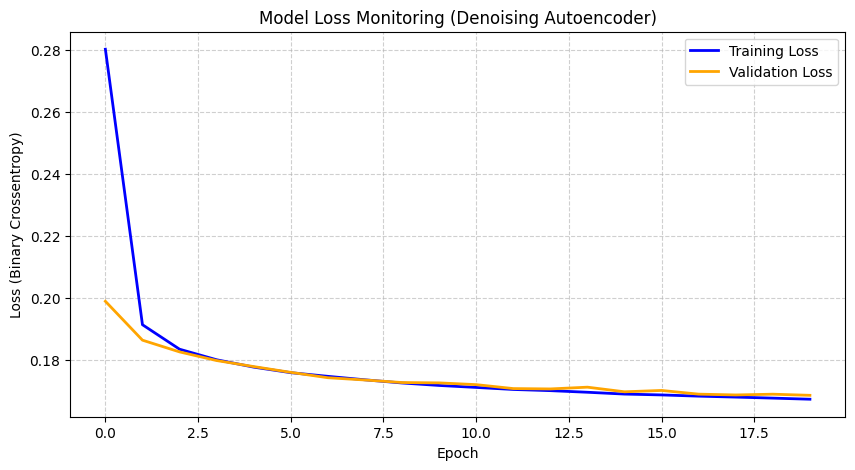

In [ ]:
# We use x_train_noisy as input and the original x_train as the target
history = autoencoder.fit(
    x_train_noisy, x_train,
    epochs=20,
    batch_size=128,
    shuffle=True,
    validation_data=(x_val_noisy, x_val),
    verbose=1
)

def plot_training_history(history):
    plt.figure(figsize=(10, 5))

    #Plot Training & Validation Loss
    plt.plot(history.history['loss'], label='Training Loss', color='blue', lw=2)
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange', lw=2)

    plt.title('Model Loss Monitoring (Denoising Autoencoder)')
    plt.ylabel('Loss (Binary Crossentropy)')
    plt.xlabel('Epoch')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()
plot_training_history(history)

4. Evaluate and Visualize the Results:


125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


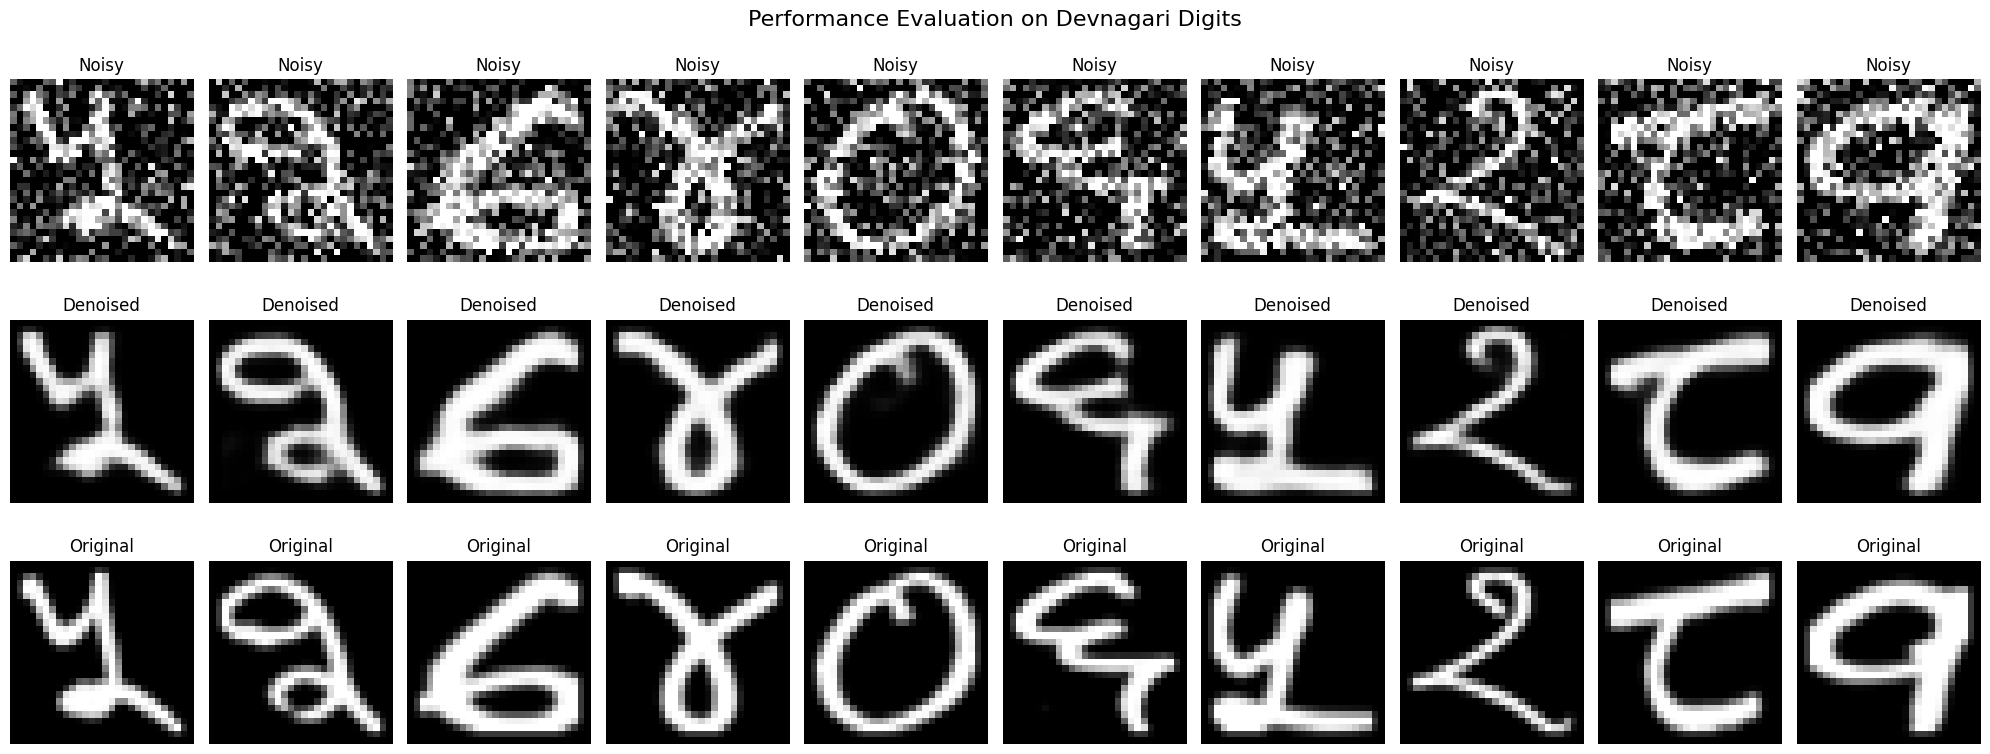

In [ ]:
# Generate denoised images from the validation set
denoised_images = autoencoder.predict(x_val_noisy)

def visualize_results(noisy, denoised, original, n=10):
    """
    Visualizes the transition from noisy to denoised compared to the original.
    """
    plt.figure(figsize=(20, 8))
    for i in range(n):
        #display noisy images
        ax = plt.subplot(3, n, i + 1)
        plt.imshow(noisy[i].reshape(28, 28), cmap='gray')
        plt.title("Noisy")
        plt.axis('off')

        #display denoised image
        ax = plt.subplot(3, n, i + 1 + n)
        plt.imshow(denoised[i].reshape(28, 28), cmap='gray')
        plt.title("Denoised")
        plt.axis('off')

        #display clean image
        ax = plt.subplot(3, n, i + 1 + 2 * n)
        plt.imshow(original[i].reshape(28, 28), cmap='gray')
        plt.title("Original")
        plt.axis('off')
    plt.suptitle("Performance Evaluation on Devnagari Digits", fontsize=16)
    plt.tight_layout()
    plt.show()
#visualization of first 10 images from the validation set
visualize_results(x_val_noisy, denoised_images, x_val, n=10)

5. Experiment and Fine - Tune the Model:



In [ ]:
def build_tuned_autoencoder(input_shape=(28, 28, 1)):
    input_img = Input(shape=input_shape)

    # Deeper Encoder with more filters 32 - 64 - 128
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)

    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)

    #deeper decoder
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)

    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    model = Model(input_img, decoded)
    model.compile(optimizer=Adam(learning_rate=0.0005), loss='binary_crossentropy')
    return model

new_noise_factor = 0.25
x_train_noisy_low = np.clip(x_train + new_noise_factor * np.random.normal(0, 1, x_train.shape), 0., 1.)
x_val_noisy_low = np.clip(x_val + new_noise_factor * np.random.normal(0, 1, x_val.shape), 0., 1.)

tuned_model = build_tuned_autoencoder()
tuned_history = tuned_model.fit(
    x_train_noisy_low, x_train,
    epochs=15,
    batch_size=64,
    validation_data=(x_val_noisy_low, x_val),
    verbose=1
)

Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.3250 - val_loss: 0.1686
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.1663 - val_loss: 0.1617
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1605 - val_loss: 0.1586
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1581 - val_loss: 0.1571
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1563 - val_loss: 0.1562
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1552 - val_loss: 0.1549
Epoch 7/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1541 - val_loss: 0.1541
Epoch 8/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.1533 - val_loss: 0.1537
Epoch 9/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1527 - val_loss: 0.1531
Epoch 10/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1524 - val_loss: 0.1525
Epoch 11/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1519 - val_loss: 0.1521
Epoch 12/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/ste